# CircuitEvolve-CV: LLM-evolved, certified rules for hybrid CV-DV Hamiltonian simulation
*Progress demo — 2026-10-13*

**Goal.** A self-evolving rulebook for compiling hybrid qubit–oscillator (CV-DV) Hamiltonian simulation,
with four stages: **mutator** (LLM proposes rules) → **verifier** (frozen, certified error bound) →
**metrics** (Genesis cost model) → **selector** (append a rule only if it helps).
Baseline: **Genesis** (Chen et al., ISCA'25, arXiv:2505.13683). Target ISA: phase-space + beam splitter
{qubit rotations, R, D, BS, CR, CP, CD} (Liu et al., arXiv:2407.10381).

**Key results so far**
1. Genesis metrics reproduced exactly (our independent implementation = Genesis `--stats` on all 20 outputs).
2. Genesis outputs are **not correct** under its own Table-2 gate definitions on 5 of 6 model families
   (even-weight Pauli strings, n² terms, routing SWAP phase).
3. Our compiler attaches a **certified worst-case error bound** to every term (bounded-photon subspace).
4. Rulebook = Genesis-derived base rules + LLM-added rules with provenance. One LLM-session rule
   (n² via parity) is exact on n ≤ 3 with 3 two-op gates (Genesis: 6, and incorrect).
5. First automated LLM campaign on generic-angle n² (n ≤ 15): loop works end-to-end, **0/24 accepted** —
   this is the open problem for the next phase.


In [1]:
import os, sys, json, time, subprocess, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
sys.path.insert(0, os.path.join(ROOT, 'experiments'))
from cvdv import qasm, sim, target, metrics, terms as T, certify as C, library as L, compiler as CO, \
    verify, route as RT, unit_terms as UT, isa
RES = os.path.join(ROOT, 'results'); RB = os.path.join(ROOT, 'rulebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 9, 'axes.titlesize': 10})
GEN, OURS, LLMC, GREY = '#d95f02', '#1b9e77', '#7570b3', '#7f7f7f'
# integrity of the frozen verifier stack
print(subprocess.run(['shasum', '-a', '256', '-c', 'FROZEN.sha256'], cwd=ROOT, capture_output=True, text=True).stdout)

src/cvdv/certify.py: OK
src/cvdv/sim.py: OK
src/cvdv/spec.py: OK
src/cvdv/terms.py: OK
src/cvdv/isa.py: OK
src/cvdv/metrics.py: OK
src/cvdv/qasm.py: OK
src/cvdv/target.py: OK
src/cvdv/verify.py: OK
src/cvdv/library.py: OK
src/cvdv/unit_terms.py: OK
tests/test_acceptance.py: OK



## 1. Baseline: reproducing Genesis
Genesis metrics (§4.1): **1-op gates**, **2-op gates**, **duration** = critical path with latency 1 (1-op) / 20 (multi-op),
on the routed physical circuit. Our `metrics.py` is an independent re-implementation.

,benchmark,paper_gates,ours_gates,paper_duration,ours_duration,dur_diff_%,genesis_stats_match
0,kerr_1,595,595.0,3032,3032.0,0.0,True
1,z2Higgs_1,696,681.0,943,877.0,-7.0,True
2,z2Higgs_2,1472,1451.0,1797,1812.0,0.8,True
3,z2Higgs_3,2263,2245.0,2721,2676.0,-1.7,True
4,boseHubbard_1,2935,2971.0,15353,13607.0,-11.4,True
5,boseHubbard_2,15313,13939.0,62548,64472.0,3.1,True
6,boseHubbard_3,36705,36930.0,155872,143170.0,-8.1,True
7,hubbardHolstein_1,688011,684810.0,4509157,4472584.0,-0.8,True
8,electronicVibration_1,5635,5593.0,28551,23890.0,-16.3,True
9,electronicVibration_2,12655,12739.0,54952,50604.0,-7.9,True


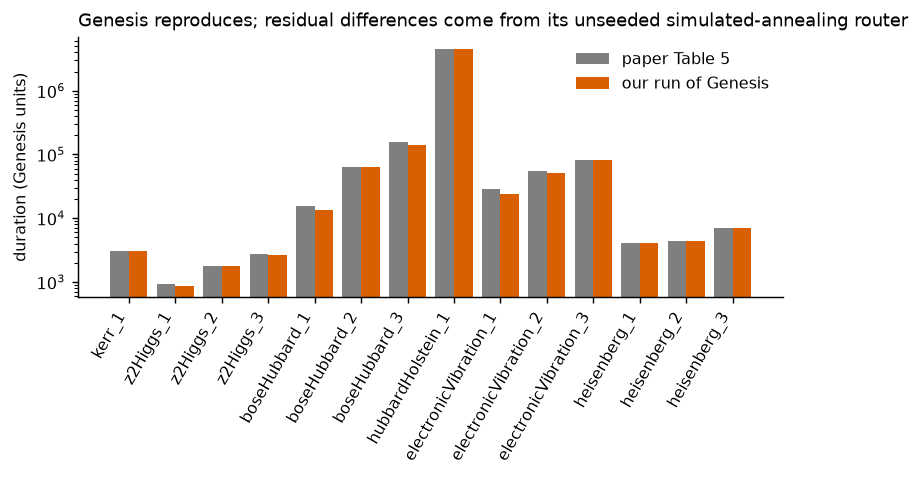

In [2]:
t5 = pd.read_csv(os.path.join(RES, 'genesis_table5_repro.csv'))
t5['dur_diff_%'] = (100 * (t5.ours_duration - t5.paper_duration) / t5.paper_duration).round(1)
display(t5[['benchmark', 'paper_gates', 'ours_gates', 'paper_duration', 'ours_duration', 'dur_diff_%', 'genesis_stats_match']])
fig, ax = plt.subplots(figsize=(7, 2.6))
x = np.arange(len(t5))
ax.bar(x - 0.2, t5.paper_duration, 0.4, color=GREY, label='paper Table 5')
ax.bar(x + 0.2, t5.ours_duration, 0.4, color=GEN, label='our run of Genesis')
ax.set_yscale('log'); ax.set_xticks(x); ax.set_xticklabels(t5.benchmark, rotation=60, ha='right')
ax.set_ylabel('duration (Genesis units)'); ax.legend(frameon=False)
ax.set_title('Genesis reproduces; residual differences come from its unseeded simulated-annealing router', loc='left')
plt.show()

## 2. Correctness audit of Genesis (live)
Simulator: truncated Fock space, Genesis Table-2 conventions; results converged in the cutoff.
**(a)** Genesis' multi-Pauli exponential gadget, built directly from Genesis' own code: does the ancilla oscillator
return to vacuum?

In [3]:
import audit_genesis as AG
rows = []
for ps in ['ZIII', 'ZZII', 'ZZZI', 'XXII', 'YZII', 'XYZI']:
    nq = len(ps.rstrip('I'))
    U, vac = AG.eff_qubit_unitary(AG.gadget_ops(ps, 0.3j), nq)
    rows.append({'pauli string': ps.rstrip('I'), 'weight': nq, 'worst-case ancilla return to vacuum': round(min(vac), 4)})
display(pd.DataFrame(rows))

,pauli string,weight,worst-case ancilla return to vacuum
0,Z,1,1.0000
1,ZZ,2,0.2369
2,ZZZ,3,1.0000
3,XX,2,0.6185
4,YZ,2,0.6185
5,XYZ,3,1.0000


**(b)** Genesis' n² rule (on-site Bose-Hubbard / Z2-Higgs / Kerr): error vs angle. A correct group-commutator
approximation has infidelity ∝ θ³; Genesis' is ∝ θ² (wrong at leading order).
**(c)** Whole circuit: Genesis' compiled Heisenberg (small) vs the Trotter step it was compiled from.

Genesis heisenberg_small physical circuit: 320 gates, infidelity vs Trotter step = 1.000


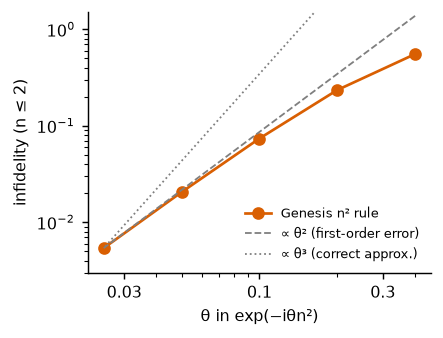

In [4]:
aud = json.load(open(os.path.join(RES, 'genesis_audit.json')))
s = aud['n2_scaling']; th = np.array([r['theta'] for r in s]); inf = np.array([r['infid_sys'] for r in s])
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.loglog(th, inf, 'o-', color=GEN, label='Genesis n² rule')
ax.loglog(th, inf[-1] * (th / th[-1])**2, '--', color=GREY, lw=1, label='∝ θ² (first-order error)')
ax.loglog(th, inf[-1] * (th / th[-1])**3, ':', color=GREY, lw=1, label='∝ θ³ (correct approx.)')
from matplotlib.ticker import NullFormatter
ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticks([0.03, 0.1, 0.3]); ax.set_xticklabels(['0.03', '0.1', '0.3'])
ax.set_ylim(3e-3, 1.5); ax.set_xlabel('θ in exp(−iθn²)'); ax.set_ylabel('infidelity (n ≤ 2)'); ax.legend(frameon=False, fontsize=7)
plt.show()

name = 'heisenberg_small'; d = os.path.join(RES, 'genesis_seeded_s0', name)
terms_h = target.read_intermediate(f'{d}/intermediate_{name}.cvdvqasm')
gphys = qasm.read(f'{d}/{name}.cvdvqasm').ops
fmap = {tuple(l): tuple(p) for l, p in json.load(open(f'{d}/{name}.cvdvqasm.mapping.json'))['final_log_to_phys']}
r = verify.verify(terms_h, gphys, N=14, n_probes=2, final_map=fmap)
print(f"Genesis heisenberg_small physical circuit: {len(gphys)} gates, infidelity vs Trotter step = {r['max_infid_strict']:.3f}")

## 3. Our verifier: a certified error bound per term
For term exp(−iH) and emitted gates V (system + ancillas in |0⟩):

$$\varepsilon=\min_\varphi\ \max_{|\psi\rangle\in S}\ \big\|V(|\psi\rangle|0\rangle)-e^{i\varphi}\,e^{-iH}|\psi\rangle|0\rangle\big\|,\qquad S=\{\text{total photons}\le n_{\max}\}\otimes\text{qubits}$$

* worst case over the whole subspace (not sampled states); ancilla garbage counts as error;
* computed at increasing cutoffs until two agree; for number-conserving terms the bounds **add** over a Trotter step;
* frozen by hash after an acceptance suite with planted bugs (wrong BCH sign, Genesis-style gadget, truncation-edge-only identity, ancilla left excited, 1e-5 angle error, …).

Live: certify every Genesis-derived base rule on canonical terms.

In [5]:
rb_src = open(os.path.join(RB, 'rules.py')).read(); RULES = L.load(rb_src)
def emit_cert(fn, H, n_max=3, r=1):
    part = T.classify(H)[0]; ws = H.wires()
    nq = max([w[1]+1 for w in ws if w[0]=='q'], default=0); nm = max([w[1]+1 for w in ws if w[0]=='qm'], default=0)
    comp = CO.Compiler({}, n_max=n_max, n_sys_q=nq, n_sys_m=nm)
    ops = comp.emit(part, fn, r)
    return ops, C.certify(H, ops, part.kind, n_max=n_max)
rows = []
for name, H in UT.cases():
    if name.startswith('n2'): continue
    kind = T.classify(H)[0].kind
    for rn, fn in RULES[kind]:
        try: ops, c = emit_cert(fn, H)
        except ValueError: continue
        m = metrics.metrics(ops)
        rows.append({'term': name, 'rule': rn, 'gates': m['total'], '2-op': m['two_op'], 'eps (n<=3)': f"{c['eps']:.1e}"})
display(pd.DataFrame(rows))

,term,rule,gates,2-op,eps (n<=3)
0,n,R,1,0,1.8e-16
1,hop,BS,1,1,1.6e-16
2,z_n,CR,1,1,2.2e-16
3,z_hop,cp_conj,3,3,6.0e-16
4,disp,D,1,0,8.7e-19
5,pauli Z,rot,1,0,0.0e+00
6,pauli Z,qumode_commutator,8,4,2.7e-10
7,pauli X,rot,1,0,0.0e+00
8,pauli X,qumode_commutator,10,4,2.7e-10
9,pauli Y,rot,1,0,0.0e+00


In [6]:
# acceptance suite of the frozen stack (planted bugs must be caught)
out = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/test_acceptance.py'], cwd=ROOT, capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

28 passed in 135.34s (0:02:15)


## 4. The self-evolving rulebook
`rulebook/rules.py` (append-only), `ledger.jsonl` (provenance + evidence), `playbook.md` (insights the mutator reads).

In [7]:
ledger = pd.DataFrame([json.loads(l) for l in open(os.path.join(RB, 'ledger.jsonl'))])
display(ledger[['rule', 'kind', 'origin', 'added']])
print(open(os.path.join(RB, 'playbook.md')).read())

# CV-DV rulebook playbook (insights for the mutator; append-only, curated)

1. Conventions: R(θ)=e^{-iθn}, CR(θ)=e^{-iθ/2 σz n}, CP=CR(π), D(α)=e^{αa†-α*a}, CD(α)=e^{σz(αa†-α*a)},
   BS(θ,φ)=e^{-iθ/2(e^{iφ}a†b+h.c.)}. Rules are executed in time order (first call acts first).
2. Conjugation by W = exp(-iπ/2 σx n) = H·CP·H maps σz -> (-1)^n σz exactly; it lets diagonal ancilla phases
   become parity-weighted functions of n (basis of rule_n2__parity_exact).
3. Group commutators e^{A}e^{B}e^{-A}e^{-B} of σ·n generators give σz n² only to first order; certified
   error falls as r^{-1/2} with r repetitions, which is far too slow at n_max >= 7.
4. The certificate is worst-case over all states with total photon number <= n_max, ancilla must return to |0>.
   Exploit exactness on a bounded subspace; do not rely on small-n behaviour only.
5. [RETRACTED by curator 2026-10-13: the seed group commutator is algebraically correct (verified, error ∝ r^{-1/2} at small θ·n²); the plateau at n_max >= 5

,rule,kind,origin,added
0,rule_n__R,n,genesis-derived,2026-10-13
1,rule_hop__BS,hop,genesis-derived,2026-10-13
2,rule_z_n__CR,z_n,genesis-derived,2026-10-13
3,rule_z_hop__cp_conj,z_hop,genesis-derived,2026-10-13
4,rule_disp__D,disp,genesis-derived,2026-10-13
5,rule_pauli__rot,pauli,genesis-derived,2026-10-13
6,rule_pauli__qumode_commutator,pauli,genesis-derived,2026-10-13
7,rule_pauli_disp__cd,pauli_disp,genesis-derived,2026-10-13
8,rule_n2__group_commutator,n2,genesis-derived,2026-10-13
9,rule_n2__parity_exact,n2,llm-session,2026-10-13


## 5. An LLM-contributed rule: exp(−iθn²) via photon parity
Identity on n ≤ 3: $n^2=-\tfrac32+3n+\tfrac32(-1)^n-n(-1)^n$. Conjugation by $W=e^{-i\frac{\pi}{2}\sigma_x n}=H\,\mathrm{CP}\,H$
maps σz → (−1)ⁿσz on the ancilla, so diagonal ancilla phases become parity-weighted.
Cost: **3 two-op + 6 one-op gates**, exact. Genesis: 20 gates (6 two-op), first-order wrong.

Map of the certified error over (θ, n_max): exact for every θ when n_max ≤ 3, and exact for all n when θ is a
multiple of π/4 — which is the case for **all Genesis benchmark angles** (so the benchmarks hide the hard case).

720 certificates in 0.6s


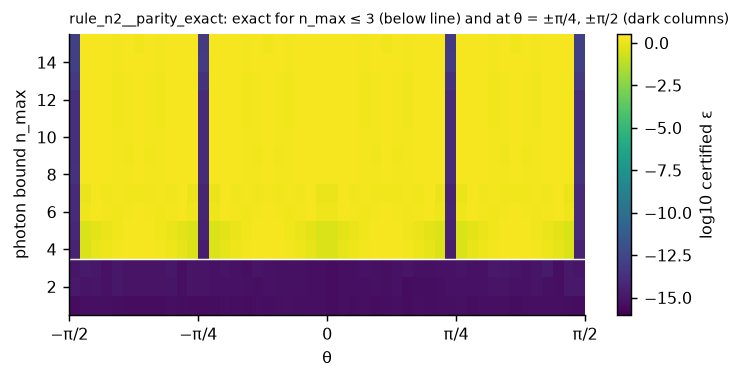

,rule,gates,2-op,duration,"eps(n<=3, θ=π/4)"
0,group_commutator,16,4,92.0,1.6e+00
1,parity_exact,9,3,65.0,6.6e-16
2,Genesis n² rule,20,6,NaN,infidelity 0.72 (n<=2)


In [8]:
fn_par = dict(RULES['n2'])['parity_exact']
thetas = np.delete(np.linspace(-np.pi/2, np.pi/2, 49), 24); nmaxes = list(range(1, 16))  # grid hits kπ/4, skips θ = 0
E = np.zeros((len(nmaxes), len(thetas)))
t0 = time.time()
for i, nm in enumerate(nmaxes):
    for j, th in enumerate(thetas):
        H = (UT.n_(0) * UT.n_(0)).scale(th)
        E[i, j] = emit_cert(fn_par, H, n_max=nm)[1]['eps']
fig, ax = plt.subplots(figsize=(6.4, 2.8))
im = ax.imshow(np.log10(np.maximum(E, 1e-16)), aspect='auto', origin='lower', cmap='viridis',
               extent=[thetas[0], thetas[-1], 0.5, 15.5], vmin=-16, vmax=0.5)
ax.set_xlabel('θ'); ax.set_ylabel('photon bound n_max'); fig.colorbar(im, label='log10 certified ε')
ax.axhline(3.5, color='w', lw=0.8)
ax.set_xticks([-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2]); ax.set_xticklabels(['−π/2', '−π/4', '0', 'π/4', 'π/2'])
ax.set_title('rule_n2__parity_exact: exact for n_max ≤ 3 (below line) and at θ = ±π/4, ±π/2 (dark columns)', loc='left', fontsize=8); plt.show()
print(f'{E.size} certificates in {time.time()-t0:.1f}s')

H = (UT.n_(0) * UT.n_(0)).scale(np.pi/4)
cmp_rows = []
for rn, fn in RULES['n2']:
    ops, c = emit_cert(fn, H, n_max=3); m = metrics.metrics(ops)
    cmp_rows.append({'rule': rn, 'gates': m['total'], '2-op': m['two_op'], 'duration': m['duration'], 'eps(n<=3, θ=π/4)': f"{c['eps']:.1e}"})
cmp_rows.append({'rule': 'Genesis n² rule', 'gates': 20, '2-op': 6, 'duration': None, 'eps(n<=3, θ=π/4)': 'infidelity 0.72 (n<=2)'})
display(pd.DataFrame(cmp_rows))

## 6. Benchmarks: certified compile vs Genesis (small instances, n_max = 3, ε = 1e-3)
Our logical circuit is routed with **Genesis' own router** (same options), only its SWAP phase is corrected
(BS(π,0)·R(−π/2)⊗R(−π/2)). Live: compile + route + independently verify Heisenberg.

In [9]:
import common as X
tl, ops, rep, comp = X.compile_bench('heisenberg_small', RULES, eps=1e-3, n_max=3)
display(pd.DataFrame(rep['parts'])[['term', 'kind', 'rule', 'r', 'eps', 'n_ops']].head(6))
phys, info = RT.route(ops)
r = verify.verify(tl, phys, N=14, n_probes=2, final_map=info['final_map'])
print(f"ours: {metrics.metrics(phys)}  certified bound = {rep['eps_bound']:.1e}  independent check infidelity = {r['max_infid_strict']:.1e}")
phys_bad, info_bad = RT.route(ops, fix_swaps=False)
r_bad = verify.verify(tl, phys_bad, N=14, n_probes=2, final_map=info_bad['final_map'])
print(f"same circuit with Genesis' original SWAP: infidelity = {r_bad['max_infid_strict']:.3f}")

ours: {'one_op': 264, 'two_op': 166, 'total': 430, 'duration': 3449}  certified bound = 8.8e-15  independent check infidelity = 2.9e-12
same circuit with Genesis' original SWAP: infidelity = 0.957


,term,kind,rule,r,eps,n_ops
0,0,pauli,qumode_commutator,1,1.066427e-15,16
1,1,pauli,qumode_commutator,1,1.066427e-15,20
2,2,pauli,qumode_commutator,1,8.032141e-16,12
3,3,pauli,qumode_commutator,1,1.066427e-15,16
4,4,pauli,qumode_commutator,1,1.066427e-15,20
5,5,pauli,qumode_commutator,1,8.032141e-16,12


,benchmark,compiler,one_op,two_op,duration,eps_bound,note
0,kerr_small,Genesis (uncertified),453.0,142.0,3032.0,NaN,physical
1,kerr_small,seed,NaN,NaN,NaN,NaN,"infeasible: no rule meets eps share 1.00e-03 for n2(('qm', 0),)(0.785398"
2,kerr_small,seed+parity,8.0,3.0,66.0,1.883144e-15,bound valid; 0.0s
3,boseHubbard_small,Genesis (uncertified),72.0,40.0,438.0,NaN,physical
4,boseHubbard_small,seed,NaN,NaN,NaN,NaN,"infeasible: no rule meets eps share 2.50e-04 for n2(('qm', 0),)(0.785398"
5,boseHubbard_small,seed+parity,40.0,28.0,371.0,7.532576e-15,bound valid; 2.1s
6,z2Higgs_small,Genesis (uncertified),78.0,41.0,321.0,NaN,physical
7,z2Higgs_small,seed,NaN,NaN,NaN,NaN,"infeasible: no rule meets eps share 2.50e-04 for n2(('qm', 0),)(1.570796"
8,z2Higgs_small,seed+parity,61.0,38.0,458.0,1.235453e-14,bound valid; 253.9s
9,heisenberg_small,Genesis (uncertified),184.0,136.0,1810.0,NaN,physical


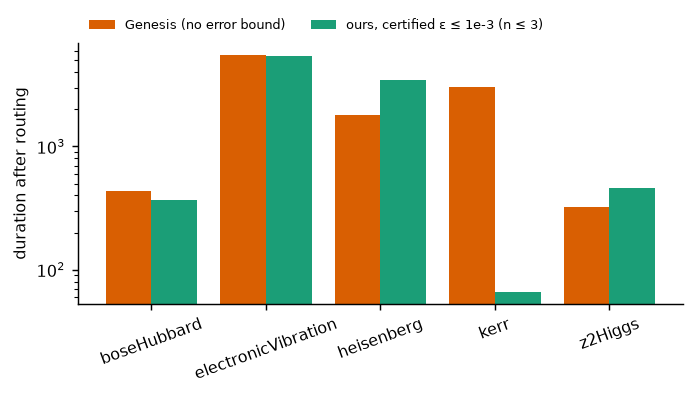

In [10]:
snap = pd.read_csv(os.path.join(RES, 'snapshot_small_nmax3.csv'))
display(snap)
piv = snap[snap.compiler.isin(['Genesis (uncertified)', 'seed+parity'])].pivot(index='benchmark', columns='compiler', values='duration')
fig, ax = plt.subplots(figsize=(6, 2.6)); x = np.arange(len(piv))
ax.bar(x - 0.2, piv['Genesis (uncertified)'], 0.4, color=GEN, label='Genesis (no error bound)')
ax.bar(x + 0.2, piv['seed+parity'], 0.4, color=OURS, label='ours, certified ε ≤ 1e-3 (n ≤ 3)')
ax.set_xticks(x); ax.set_xticklabels([b.replace('_small', '') for b in piv.index], rotation=20)
ax.set_yscale('log'); ax.set_ylabel('duration after routing'); ax.legend(frameon=False, fontsize=7, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2); plt.show()

Same comparison in **gate counts** (Genesis reports both). 2-op gates (qubit–oscillator or oscillator–oscillator)
dominate both runtime and error on hardware, so they are shown separately from 1-op gates.

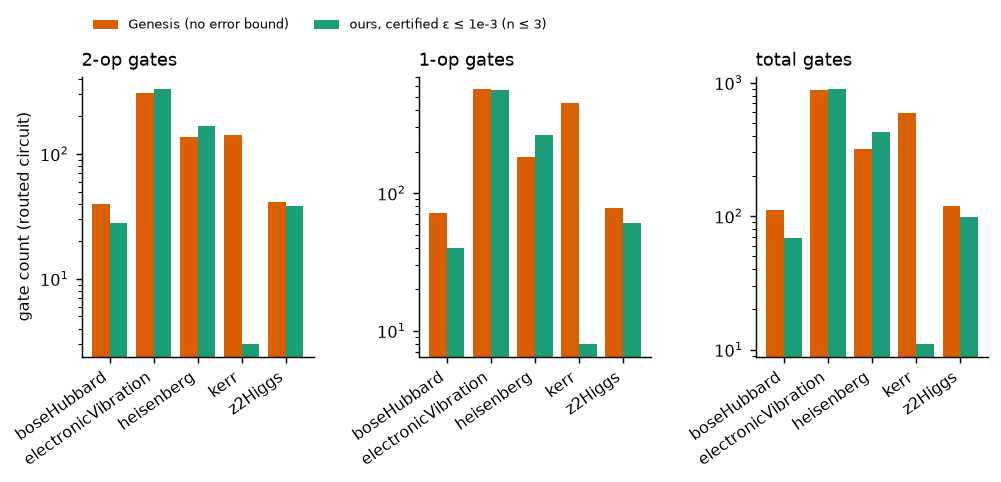

,two_op ratio ours/Genesis,one_op ratio ours/Genesis,total ratio ours/Genesis
benchmark,,,
boseHubbard_small,0.70,0.56,0.61
electronicVibration_small,1.08,0.99,1.02
heisenberg_small,1.22,1.43,1.34
kerr_small,0.02,0.02,0.02
z2Higgs_small,0.93,0.78,0.83


In [11]:
gc = snap[snap.compiler.isin(['Genesis (uncertified)', 'seed+parity'])]
fig, axs = plt.subplots(1, 3, figsize=(9, 2.8), gridspec_kw=dict(wspace=0.45))
labels = {'Genesis (uncertified)': 'Genesis (no error bound)', 'seed+parity': 'ours, certified ε ≤ 1e-3 (n ≤ 3)'}
for ax, col, ttl in zip(axs, ['two_op', 'one_op', None], ['2-op gates', '1-op gates', 'total gates']):
    p = gc.assign(total=gc.one_op + gc.two_op).pivot(index='benchmark', columns='compiler', values=col or 'total')
    x = np.arange(len(p))
    for k, (cname, color) in enumerate([('Genesis (uncertified)', GEN), ('seed+parity', OURS)]):
        ax.bar(x + (k - 0.5) * 0.4, p[cname], 0.4, color=color, label=labels[cname])
    ax.set_yscale('log'); ax.set_title(ttl, loc='left'); ax.set_xticks(x)
    ax.set_xticklabels([b.replace('_small', '') for b in p.index], rotation=35, ha='right')
axs[0].set_ylabel('gate count (routed circuit)')
axs[0].legend(frameon=False, fontsize=7, loc='lower left', bbox_to_anchor=(0, 1.12), ncol=2)
plt.show()
t = gc.assign(total=gc.one_op + gc.two_op).pivot(index='benchmark', columns='compiler', values=['two_op', 'one_op', 'total'])
ratio = (t.xs('seed+parity', axis=1, level=1) / t.xs('Genesis (uncertified)', axis=1, level=1)).round(2)
ratio.columns = [f'{c} ratio ours/Genesis' for c in ratio.columns]; display(ratio)

Reading: Kerr (0.02× gates) and Bose-Hubbard (0.61×) win on both metrics (n² via parity rule). Z2-Higgs uses
fewer gates than Genesis (0.83×) but has a longer duration: our ISA has no conditional beam splitter, so it is built
from 3 gates in series (CP·BS·CP†), which lengthens the critical path even though the count drops. Heisenberg loses because the seed Pauli gadget's ancilla
oscillator shuttles between qubit sites — a routing-aware rule is an open LLM target. **Caveat:** at the Genesis
benchmark angles the parity rule is exact for all n; generic angles are the real test (next section).

## 7. Automated LLM campaign (pilot): n² at generic angles
Instances: θ ∈ {0.03, 0.137, −0.25, 0.4} × n_max ∈ {5, 7, 15}, ε_share = 1e-4. Mutator: reasoning-class LLM,
one-shot proposals (6 per round, 4 rounds) with the DSL, conventions, current rules + scores, playbook and history.

{'rejected': 17, 'no code': 7} | decline rules: 10


,round,slot,rule,status,declined,best eps(r=1),feasible instances
0,0,0,symmetric_group_commutator,rejected,False,0.597392,0
1,0,1,quad_parity_two_anc,rejected,False,NaN,0
2,0,2,decline_slot,rejected,True,NaN,0
3,0,3,,no code,False,NaN,0
4,0,4,sym_group_commutator,rejected,False,0.479468,0
5,0,5,sym_group_commutator,rejected,False,0.877691,0
6,1,0,symmetrized_group_commutator_v2,rejected,False,0.817525,0
7,1,1,decline_binary_phase_needs_2q,rejected,True,NaN,0
8,1,2,,no code,False,NaN,0
9,1,3,,no code,False,NaN,0


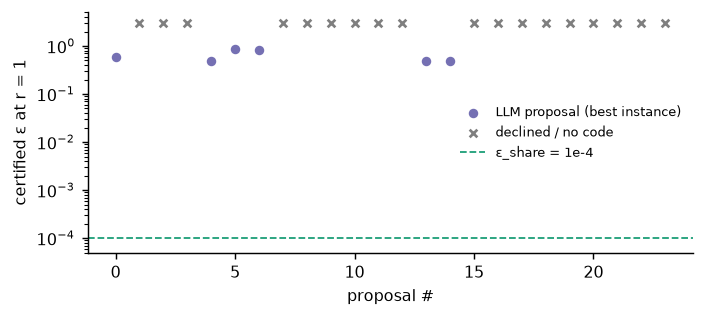

In [12]:
recs = [json.loads(l) for l in open(os.path.join(RES, 'evolve', 'pilot2_n2', 'log.jsonl'))]
rows = []
for r_ in recs:
    sc = r_.get('scores') or []
    e1 = [s.get('eps_r1') for s in sc if s.get('eps_r1') is not None]
    nm = r_.get('name') or ''
    rows.append({'round': r_['round'], 'slot': r_['slot'], 'rule': nm.replace('rule_n2__', ''), 'status': r_['status'],
                 'declined': 'decline' in nm, 'best eps(r=1)': min(e1) if e1 else np.nan,
                 'feasible instances': sum(bool(s.get('feasible')) for s in sc)})
camp = pd.DataFrame(rows); display(camp)
print(camp.status.value_counts().to_dict(), '| decline rules:', int(camp.declined.sum()))
fig, ax = plt.subplots(figsize=(6, 2.4))
ok = camp['best eps(r=1)'].notna()
ax.scatter(camp.index[ok], camp['best eps(r=1)'][ok], color=LLMC, s=18, label='LLM proposal (best instance)')
ax.scatter(camp.index[~ok], np.full((~ok).sum(), 3.0), marker='x', color=GREY, s=18, label='declined / no code')
ax.axhline(1e-4, color=OURS, ls='--', lw=1, label='ε_share = 1e-4')
ax.set_yscale('log'); ax.set_ylim(5e-5, 5); ax.set_xlabel('proposal #'); ax.set_ylabel('certified ε at r = 1')
ax.legend(frameon=False, fontsize=7, loc='center right'); plt.show()

In [13]:
# one representative LLM proposal (as submitted) and its certified outcome
ex = next(r_ for r_ in recs if r_.get('code') and 'decline' not in (r_.get('name') or ''))
print(ex['code'][:1800])
print('\n'.join(f"  instance {i}: eps(r=1)={s.get('eps_r1', float('nan')):.2e}  feasible={s.get('feasible')}" for i, s in enumerate(ex['scores'][:4])))

def rule_n2__symmetric_group_commutator(t, g, r):
    # H = θ n². Symmetrized (palindromic) group-commutator product:
    # forward sweep [e^{B}e^{A}e^{-B}e^{-A}] then backward sweep [e^{A}e^{B}e^{-A}e^{-B}]
    # with HALF angle each, canceling the leading (odd-order in x) BCH error term
    # that plagues the plain group_commutator rule, giving faster convergence in r.
    # A = -i x σx n, B = -i x σy n on ancilla |0>; e^{[A,B]} = e^{-2i x² σz n²}.
    # Using half-steps x/√2 in each half-sweep keeps total accumulated σz n² phase
    # equal to a single step of x (since (x/√2)² * 2 = x²), while the symmetric
    # (palindromic) ordering cancels the leading BCH correction term.
    a = g.anc_qubit()
    md = t.m[0]
    sx = 1 if t.theta >= 0 else -1
    x = m.sqrt(abs(t.theta) / (2 * r))
    xh = x / m.sqrt(2.0)

    def seg(order, sign):
        # order: list of (which, local_sign) in time-order; which: 0->A(σx), 1->B(σy)
        for which, lsign in order:
            w = which
     

**Findings from the pilot**
* The loop runs end to end (propose → static check → certify on 12 instances → select → playbook reflection).
* Generic-angle n² at n ≤ 15 is hard: proposals stayed at ε ≈ 0.5–2; 10/24 proposals explicitly declined.
* The reflection step added one correct insight (x·n_max barrier) and one wrong one, which a curator retracted
  → auto-insights need verification before entering the playbook.

## 8. Proposed next steps (for discussion)
1. **Agentic mutator with a numerical workbench** (simulate/certify drafts before submitting), as in the DV `evolve_opt` harness.
2. **Curriculum** on the photon bound: n_max 3 → 5 → 7 → 15, carrying rules and playbook forward.
3. Easier, high-value targets in parallel: routing-aware Pauli gadget ordering (Heisenberg), conditional-beam-splitter
   synthesis in PS_BS (Z2-Higgs), cross-term peephole (merge commuting R / duplicated hopping terms).
4. Classical comparison arms (hand-written peephole, higher-order commutator formulas, numerical angle optimisation)
   at matched budget; held-out Hamiltonian families.
5. Full-size benchmarks (L = 20/40/60) once the rulebook covers all term kinds at generic angles.
